# Домашнее задание 2. Работа с изображениями

В этом задании предлагается решить простейшую задачу рапознавания лиц. Вам нужно будет научить модель для пары картинок определять, разные ли люди на них изображены.

Работать будем с датасетом фотографий известных людей. Скачать его можно [тут](https://disk.360.yandex.ru/d/oAmJgPESjP33hg). В нём представлены 150 человек, для каждого по 6-9 фотографий. Всего около 1000 изображений.

__Задание__. Вам потребуется выполнить два задания:

1) Реализовать модель бинарной классификации и добиться приемлемого качества.

2) Реализовать триплетную функцию потерь и улучшить качество предсказаний с ее помощью.

Напишите краткий отчёт о проделанных экспериментах. Что сработало и что не сработало? Почему вы решили, сделать так, а не иначе? Обязательно указывайте ссылки на чужой код, если вы его используете. Обязательно ссылайтесь на статьи / блогпосты / вопросы на stackoverflow / видосы от ютуберов-машинлернеров / курсы / подсказки от Дяди Васи и прочие дополнительные материалы, если вы их используете.

__Во всех заданиях будем придерживаться следующих правил__:
1. Использовать внешние данные для обучения строго запрещено. Также запрещено обучаться на валидационной выборке.
2. Все задания должны быть выполнены без использования предобученных моделей и готовых реализаций. Тем не менее:
    - В заданиях, где требуется достичь некоторого качества модели, разрешается использовать предобученные модели. Но __оценка за задние будет снижена__ (для каждого задания будет отдельно указано, на сколько).
    - В некоторых заданиях может сильно помочь библотека [pytorch-metric-learning](https://kevinmusgrave.github.io/pytorch-metric-learning/). Вы можете использовать готовые реализации из неё, но __максимальный балл за задание также будет снижен__.

__Советы и указания__:
 - Наверняка вам потребуется много гуглить о том, как заставить это всё работать. Это нормально, все гуглят. Но не забывайте, что нужно быть готовым за скатанный код отвечать :)
 - Рекомендуем использовать шаблоны ниже. Однако делать это мы не заставляем. Если вам так неудобно, то можете писать код в удобном стиле. Однако учтите, что чрезмерное изменение нижеперечисленных шаблонов увеличит количество вопросов к вашему коду :)
 - Валидируйте. Трекайте ошибки как можно раньше, чтобы не тратить время впустую.
 - Чтобы быстро отладить код, пробуйте обучаться на маленькой части датасета (скажем, 5-10 картинок просто чтобы убедиться что код запускается). Когда вы поняли, что смогли всё отдебажить, переходите обучению по всему датасету
 - На каждый запуск делайте ровно одно изменение в модели/аугментации/оптимайзере, чтобы понять, что и как влияет на результат.
 - Фиксируйте random seed.
 - Правильно нормализуйте данные при создании, пример [тык, но тут и в целом гайд от и до](https://www.pluralsight.com/guides/image-classification-with-pytorch)
 - Начинайте с простых моделей и постепенно переходите к сложным. Обучение лёгких моделей экономит много времени. Можно написать свою модель руками, а можно импортировать не предобученную сетку известной архитектуры из модуля `torchvision.models`. Один из способов как можно сделать: [документация (полезная)](https://pytorch.org/vision/stable/models.html)
 - Используйте все возможные методы оптимизации и эксперемнтируйте с ними.
 - Ставьте расписание на learning rate. Уменьшайте его, когда лосс на валидации перестаёт убывать.
 - Model Checkpointing. Сохраняйте свой прогресс (модели), чтобы когда что-то пойдет не так вы сможете начать с этого места или просто воспроизвести свои результаты модели, которые обучали.
    * Пример как можно с wandb тут: [Сохраняем лучшие модели в wandb](https://docs.wandb.ai/guides/integrations/lightning)
    * По простому можно так: [Сохраняем модели в pytorch дока](https://pytorch.org/tutorials/beginner/saving_loading_models.html)
 - Советуем использовать GPU. Если у вас его нет, используйте google colab. Если вам неудобно его использовать на постоянной основе, напишите и отладьте весь код локально на CPU, а затем запустите уже написанный ноутбук в колабе.

Good luck & have fun! :)

In [1]:
import os
import tqdm
import numpy as np
import torch
import pandas as pd
import random
import torchvision
import sklearn.metrics
import torch.utils.data
import matplotlib.pyplot as plt
import torchvision.transforms.v2 as v2

from collections import Counter

In [2]:
# Обязательно вызывайте эту функцию перед каждый запуском обучения!
# Если проверяющий не сможет воспроизвести результат, оценка за задание будет снижена.
def set_random_seed(seed: int = 239):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True

    g = torch.Generator()
    g.manual_seed(seed)
    return g

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

### [1.5 балла] Часть 1. Подготовка данных.

##### [0.5 балла] Задание 1.1. Считать датасет.

Сначала нужно считать датасет с фотографиями и посмотреть на его устройство.

In [ ]:
# https://stackoverflow.com/questions/49685924/extract-google-drive-zip-from-google-colab-notebook

!unzip data.zip

In [4]:
set_random_seed(239)

# ToTensor() я заменила из-за UserWarning'а
# CenterCrop отсюда: https://docs.pytorch.org/vision/stable/auto_examples/
# transforms/plot_transforms_illustrations.html#sphx-glr-auto-examples-transforms-plot-transforms-illustrations-py

transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True),
                        v2.CenterCrop(size=128)])

train_ds = torchvision.datasets.ImageFolder("data/training", transform = transform)
test_ds = torchvision.datasets.ImageFolder("data/testing", transform = transform)

###### Давайте посмотрим на примеры фотографий. Нарисуйте несколько.

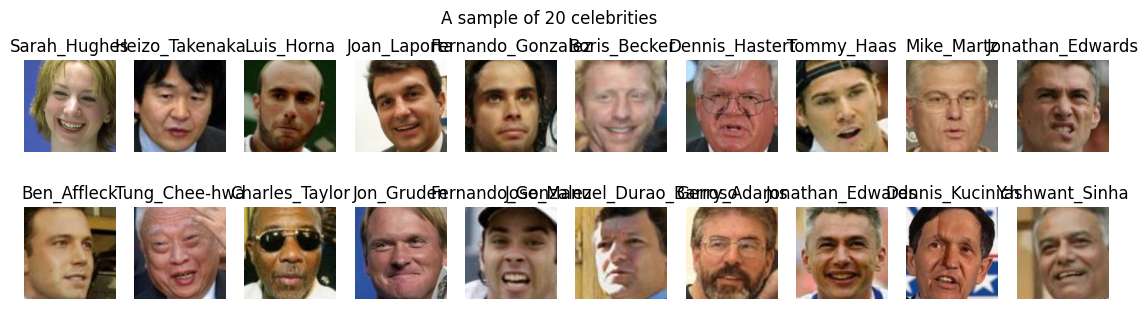

In [ ]:
def draw_image(y, x, lbl, img):
    axs[y][x].set_title(lbl)
    axs[y][x].imshow(np.transpose(img, (1, 2, 0)))
    # https://stackoverflow.com/questions/14908576/how-to-remove-frame-from-a-figure
    axs[y][x].axis('off')


train_dataloader = torch.utils.data.DataLoader(train_ds, batch_size=20,
                                               generator=set_random_seed(239),
                                               shuffle=True, num_workers=0)
set_random_seed(239)
images, labels = next(iter(train_dataloader))

fig, axs = plt.subplots(2, 10, figsize=(14, 3.5))
fig.suptitle("A sample of 20 celebrities")

for i in range(20):
    y = 0 if i < 10 else 1
    x = i if i < 10 else i - 10
    draw_image(y, x, train_ds.classes[labels[i]], images[i])

Наконец, следует вывести распределение фотографий по людям и убедиться, что для каждого человека действительно предствалено 6-9 фотографий.

In [ ]:
def show_class_distribtion(targets, title, xlabel, ylabel):
    targ_dict = Counter(targets)
    plt.figure(figsize=(10, 3))
    plt.bar(targ_dict.keys(), targ_dict.values())
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.show()

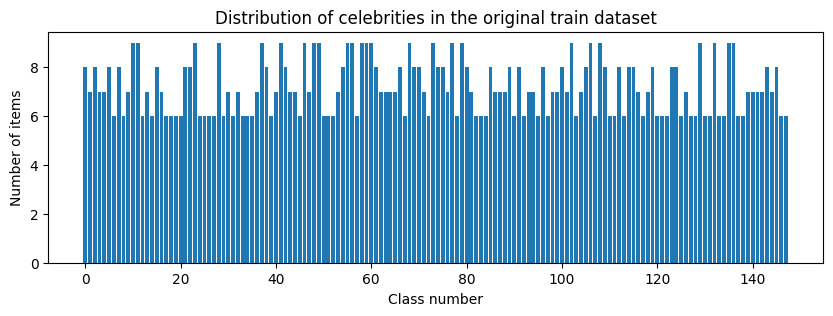

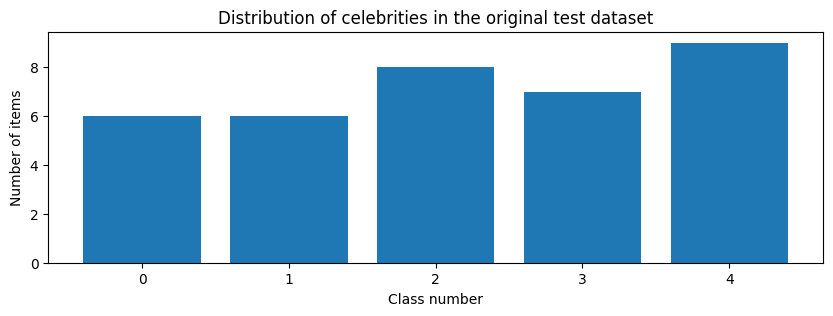

In [ ]:
show_class_distribtion(train_ds.targets, "Distribution of celebrities in the original train dataset",
                       "Class number", "Number of items")
show_class_distribtion(test_ds.targets, "Distribution of celebrities in the original test dataset",
                       "Class number", "Number of items")

##### [0 баллов] Задание 1.2. Датасет пар.

Как было сказано ранее, мы будем обучать модели предсказывать, разные ли люди изображены на фотографиях. Для этого нам надо научиться формировать пары фотографий и целевую переменную из двух классов: 0 и 1. \
Класс 0 означает, что это фотографии одного человека. \
Класс 1 означает фотографии разных людей. \
 \
К счастью, весь датасет уже написан.

In [5]:
class PairDataset(torch.utils.data.Dataset):
    def __init__(self, dataset):
        self.dataset = dataset
        self.targets = [ self._get_target(i) for i in tqdm.trange(len(self)) ]

    def _idx1(self, idx):
        return idx % len(self.dataset)

    def _idx2(self, idx):
        return idx // len(self.dataset)

    def _get_target(self, idx):
        return int(self.dataset.targets[self._idx1(idx)] != self.dataset.targets[self._idx2(idx)])

    def __len__(self):
        return len(self.dataset) ** 2

    def __getitem__(self, idx):
        image1, label1 = self.dataset[self._idx1(idx)]
        image2, label2 = self.dataset[self._idx2(idx)]
        return image1, image2, int(label1 != label2)

train_pairs = PairDataset(train_ds)
test_pairs = PairDataset(test_ds)

100%|██████████| 1296/1296 [00:00<00:00, 414473.35it/s]


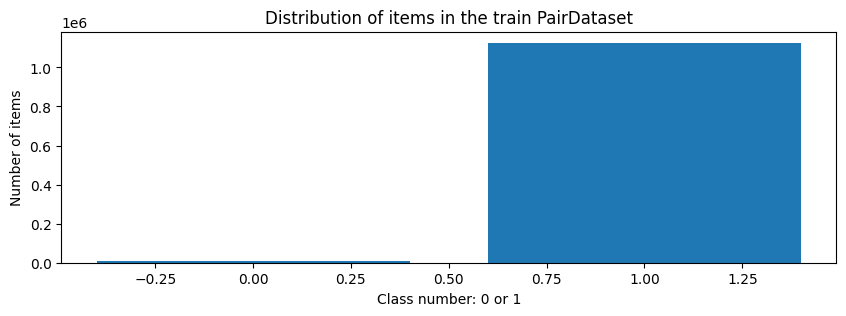

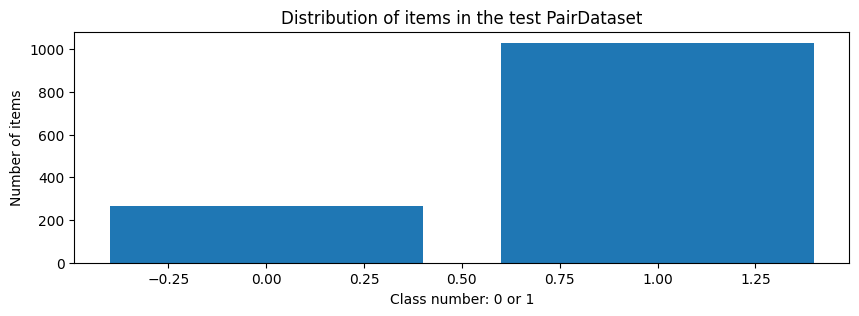

In [ ]:
show_class_distribtion(train_pairs.targets,
                       "Distribution of items in the train PairDataset",
                       "Class number: 0 or 1", "Number of items")
show_class_distribtion(test_pairs.targets,
                       "Distribution of items in the test PairDataset",
                       "Class number: 0 or 1", "Number of items")

Легко видеть, что пар фотографий разных людей гораздо больше, чем пар фотографий одного человека. Это вполне ожидаемо, но, если не предпринять мер, ведет к двум проблемам:
1. Метрика качества предсказаний должна учитывать дисбаланс классов. В частности, accuracy нам не подойдёт. А использовать будем известный из курса машинного обучения AUC-ROC.
2. Нужно "подтюнить" даталоадер тренировочных данных, чтобы в каждый батч попадало примерно одинаковое количество фотографий каждого класса. Иначе победить деградацию модели к "всегда 1" будет очень сложно.

##### [1 балл] Задание 1.3. Стратифицированный даталоадер.

Для начала решим вторую проблему. Нужно сделать такой даталоадер, чтобы в каждом батче количество элементов класса "0" совпадало с количеством элементов класса "1".

Как известно, стандартный класс `DataLoader` в torch имеет много параметров. В частности, параметр `sampler` позволяет гибко управлять выдачей. Изучите [документацию](https://docs.pytorch.org/docs/stable/data.html#data-loading-order-and-sampler) и реализуйте свой семплер, который решит проблему.

В `pytorch_metric_learning` уже есть готовая реализация того, что нам нужно. Вы можете её найти и использовать. Но в таком случае __максимальный балл за это задание - 0.4__.

In [17]:
class PairsSampler(torch.utils.data.Sampler):
    def __init__(self, data, batch_size=32, num_batches=500):
        self.data = data
        self.batch_size = batch_size
        self.num_batches = num_batches

    def __len__(self):
        return self.num_batches

    def __iter__(self):
        # Такой способ прописать заполнение батча взяла отсюда:
        # https://medium.com/@haleema.ramzan/how-to-build-a-custom-batch-sampler-in-pytorch-ce04161583ee
        batch_0, batch_1, count = [], [], 0
        half_batch = self.batch_size // 2
        for i, item in enumerate(self.data):
            if count > self.num_batches:
                break

            # Идём по лейблам и собираем 16 единичек и 16 ноликов
            if item == 1 and len(batch_1) < half_batch:
                batch_1.append(i)
            elif item == 0 and len(batch_0) < half_batch:
                batch_0.append(i)

            # Отправляем батч
            if len(batch_0 + batch_1) == self.batch_size:
                yield batch_0 + batch_1
                batch_0, batch_1 = [], []
                count += 1

In [18]:
train_pairs_sampler = PairsSampler(train_pairs.targets)

train_pairs_loader = torch.utils.data.DataLoader(train_pairs, batch_sampler=train_pairs_sampler,
                                                 generator=set_random_seed(239))
test_pairs_loader = torch.utils.data.DataLoader(test_pairs, batch_size=64,
                                                shuffle=False)

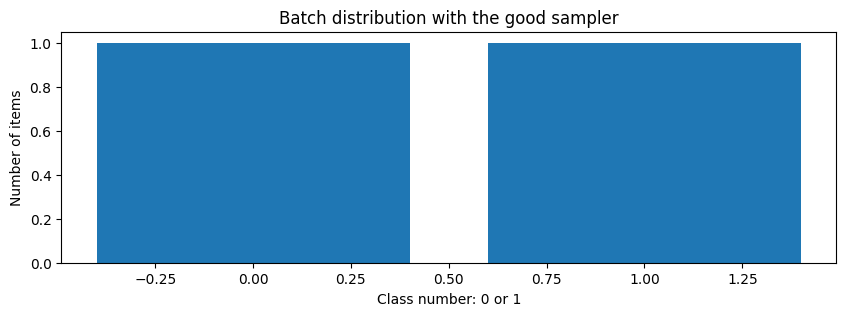

In [ ]:
# Убедимся, что теперь выдача равномерная.
show_class_distribtion(next(iter(train_pairs_loader))[2],
                       "Batch distribution with the good sampler",
                       "Class number: 0 or 1", "Number of items")

##### А теперь сделаем нормализацию и валидационную выборку.

In [8]:
# Команды линукса вспоминала по этому курсу:
# https://agricolamz.github.io/2025_morphological_transducers/05_technical_class.html

# Создаём папку validating
!mkdir 'data/validating'
# Переносим туда часть картинок из training
!bash -c 'mv /content/data/training/[PRSTVWYZ]* /content/data/validating/'

In [19]:
# Числа для Normalize взяты из гайда в начале тетрадки
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True),
                        v2.CenterCrop(size=128),
                        v2.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])

# Пересоздаём парные датасеты
train_ds = torchvision.datasets.ImageFolder("data/training", transform=transform)
val_ds = torchvision.datasets.ImageFolder("data/validating", transform=transform)
train_pairs = PairDataset(train_ds)
val_pairs = PairDataset(val_ds)

# Переопределяем семплер
train_pairs_sampler = PairsSampler(train_pairs.targets)

# Пересоздаём лоадеры
train_pairs_loader = torch.utils.data.DataLoader(train_pairs, batch_sampler = train_pairs_sampler,
                                                 generator=set_random_seed(239))
val_pairs_loader = torch.utils.data.DataLoader(val_pairs, generator=set_random_seed(239))

100%|██████████| 116281/116281 [00:00<00:00, 1227574.65it/s]


### [3.5 балла] Часть 2. Классификация.

Начнём с простого: попробуем решить проблему как обычную задачу бинарной классификации. Реализуйте и обучите обычную свёрточную сеть, которая принимает два набора фотографий и предсказывает вероятность, что это фотографии разных людей.

##### [1 балл] Задание 2.1. Модель классификации.

Сначала нужно реализовать модель. В `forward` необходимо принять два батча фотографий. `i`-e число в выводе `forward` должно быть предсказанием для пары из `i`-й фотографии `image1` и `i`-й фотографии `image2`. Подумайте, как это сделать. Возможно, стоит как-нибудь склеить `image1` и `image2`? Или склеить эмбеддинги? А может быть нужен какой-то трешхолд?

Вы вольны использовать любую архитектуру сети. Ассерт в конце ячейки поможет вам убедиться, что модель теоретически делает то, что нужно.

Подробное описание моделей и экспериментов над ними - в пункте 2.3.

In [36]:
class ClassificationNet_1(torch.nn.Module):
    def __init__(self, tensor_shape, hide_neurons):
        super().__init__()

        # Свёрточные слои
        self.conv = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=6, out_channels=36, kernel_size=5, stride=2),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Conv2d(36, 216, kernel_size=3, stride=2),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Conv2d(216, 1296, kernel_size=3),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Flatten()
        )

        # Полносвязные слои
        self.full = torch.nn.Sequential(
            torch.nn.Linear(tensor_shape, hide_neurons),
            torch.nn.Linear(hide_neurons, 1)
        )

    def forward(self, image1, image2):
        x = self.conv(torch.cat((image1, image2), dim=1))
        return self.full(x)

# Число tensor_shape я взяла из ошибки несовпадения размерностей векторов
assert ClassificationNet_1(5184, 64)(*next(iter(train_pairs_loader))[:2]).shape == (32, 1)

Во второй модели добавим нелинейности

In [32]:
class ClassificationNet_2(torch.nn.Module):
    def __init__(self, tensor_shape, hide_neurons):
        super().__init__()

        # Свёрточные слои
        self.conv = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=6, out_channels=36, kernel_size=5, stride=2),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Conv2d(36, 216, kernel_size=3, stride=2),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Conv2d(216, 1296, kernel_size=3),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Flatten()
        )

        # Полносвязные слои
        self.full = torch.nn.Sequential(
            torch.nn.Linear(tensor_shape, hide_neurons),
            torch.nn.ReLU(),
            torch.nn.Linear(hide_neurons, 1)
        )

    def forward(self, image1, image2):
        x = self.conv(torch.cat((image1, image2), dim=1))
        return self.full(x)

# Число tensor_shape я взяла из ошибки несовпадения размерностей векторов
assert ClassificationNet_2(5184, 64)(*next(iter(train_pairs_loader))[:2]).shape == (32, 1)

В третьей модели оставим нелинейности только в полносвязных слоях и добавим ещё один полносвязный слой.

In [45]:
class ClassificationNet_3(torch.nn.Module):
    def __init__(self, tensor_shape, hide_neurons):
        super().__init__()

        # Свёрточные слои
        self.conv = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=6, out_channels=36, kernel_size=5, stride=2),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Conv2d(36, 216, kernel_size=3, stride=2),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Conv2d(216, 1296, kernel_size=3),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Flatten()
        )

        # Полносвязные слои
        self.full = torch.nn.Sequential(
            torch.nn.Linear(tensor_shape, hide_neurons),
            torch.nn.ReLU(),
            torch.nn.Linear(hide_neurons, hide_neurons // 2),
            torch.nn.ReLU(),
            torch.nn.Linear(hide_neurons // 2, 1)
        )

    def forward(self, image1, image2):
        x = self.conv(torch.cat((image1, image2), dim=1))
        return self.full(x)

# Число tensor_shape я взяла из ошибки несовпадения размерностей векторов
assert ClassificationNet_3(5184, 64)(*next(iter(train_pairs_loader))[:2]).shape == (32, 1)

Как мы потом увидим, добавление полносвязного слоя не улучшило нашу модель никак. Возможно, *такое* сильное увеличение каналов слишком радикально. Попробуем уменьшить кол-во каналов в свёрточных слоях.

In [51]:
class ClassificationNet_4(torch.nn.Module):
    def __init__(self, tensor_shape, hide_neurons):
        super().__init__()

        # Свёрточные слои
        self.conv = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=6, out_channels=12, kernel_size=5, stride=2),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Conv2d(12, 24, kernel_size=3, stride=2),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Conv2d(24, 48, kernel_size=3),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Flatten()
        )

        # Полносвязные слои
        self.full = torch.nn.Sequential(
            torch.nn.Linear(tensor_shape, hide_neurons),
            torch.nn.ReLU(),
            torch.nn.Linear(hide_neurons, 1)
        )

    def forward(self, image1, image2):
        x = self.conv(torch.cat((image1, image2), dim=1))
        return self.full(x)

# Число tensor_shape я взяла из ошибки несовпадения размерностей векторов
assert ClassificationNet_4(192, 64)(*next(iter(train_pairs_loader))[:2]).shape == (32, 1)

Это сделало только хуже. Попробуем оставить MaxPooling только в конце.

In [61]:
class ClassificationNet_5(torch.nn.Module):
    def __init__(self, tensor_shape, hide_neurons):
        super().__init__()

        # Свёрточные слои
        self.conv = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=6, out_channels=12, kernel_size=5, stride=2),
            torch.nn.Conv2d(12, 24, kernel_size=3, stride=2),
            torch.nn.Conv2d(24, 48, kernel_size=3),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Flatten()
        )

        # Полносвязные слои
        self.full = torch.nn.Sequential(
            torch.nn.Linear(tensor_shape, hide_neurons),
            torch.nn.ReLU(),
            torch.nn.Linear(hide_neurons, 1)
        )

    def forward(self, image1, image2):
        x = self.conv(torch.cat((image1, image2), dim=1))
        return self.full(x)

# Число tensor_shape я взяла из ошибки несовпадения размерностей векторов
assert ClassificationNet_5(9408, 64)(*next(iter(train_pairs_loader))[:2]).shape == (32, 1)

Сделаем первую модель с ReLU в полносвязных, но с MaxPooling'ом только в конце

In [71]:
class ClassificationNet_6(torch.nn.Module):
    def __init__(self, tensor_shape, hide_neurons):
        super().__init__()

        # Свёрточные слои
        self.conv = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=6, out_channels=36, kernel_size=5, stride=2),
            torch.nn.Conv2d(36, 216, kernel_size=3, stride=2),
            torch.nn.Conv2d(216, 1296, kernel_size=3),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Flatten()
        )

        # Полносвязные слои
        self.full = torch.nn.Sequential(
            torch.nn.Linear(tensor_shape, hide_neurons),
            torch.nn.ReLU(),
            torch.nn.Linear(hide_neurons, 1)
        )

    def forward(self, image1, image2):
        x = self.conv(torch.cat((image1, image2), dim=1))
        return self.full(x)

# Число tensor_shape я взяла из ошибки несовпадения размерностей векторов
assert ClassificationNet_6(254016, 64)(*next(iter(train_pairs_loader))[:2]).shape == (32, 1)

Стало капельку лучше, чем первая модель. Добавим свёрточный слой в неё.

In [76]:
class ClassificationNet_7(torch.nn.Module):
    def __init__(self, tensor_shape, hide_neurons):
        super().__init__()

        # Свёрточные слои
        self.conv = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=6, out_channels=36, kernel_size=5, stride=2),
            torch.nn.Conv2d(36, 216, kernel_size=3, stride=2),
            torch.nn.Conv2d(216, 1296, kernel_size=3, stride=2),
            torch.nn.Conv2d(1296, 2592, kernel_size=3),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Flatten()
        )

        # Полносвязные слои
        self.full = torch.nn.Sequential(
            torch.nn.Linear(tensor_shape, hide_neurons),
            torch.nn.ReLU(),
            torch.nn.Linear(hide_neurons, 1)
        )

    def forward(self, image1, image2):
        x = self.conv(torch.cat((image1, image2), dim=1))
        return self.full(x)

# Число tensor_shape я взяла из ошибки несовпадения размерностей векторов
assert ClassificationNet_7(93312, 64)(*next(iter(train_pairs_loader))[:2]).shape == (32, 1)

##### [2 балла] Задание 2.2. Обучение.

Теперь обучите свою модель и добейтесь приемлемого качества. Балл за это задание вычисляется по формуле:

$$ clamp(0, 2.5 \cdot \dfrac{AucRoc - 0.6}{0.2}, 2.5) $$

То есть, для получения полного балла за это задание необходимо добиться AUC-ROC `0.8`

__При использовани предобученных моделей, балл за это задание умножается на 0.5__ (то есть, не более 1)

###### Функции для обучения и выводов

Функции обучения

In [21]:
def training_epoch(model, optimizer, criterion, train_loader, train_batches, tqdm_desc):
    """Одна эпоха обучения"""
    train_loss, train_accuracy = 0.0, 0.0
    model.train()

    set_random_seed(239)
    for id, (images1, images2, labels) in tqdm.tqdm(enumerate(train_loader), desc=tqdm_desc):
        if id >= train_batches:
            break

        # Переносим данные на ГПУ
        images1 = images1.to(device)
        images2 = images2.to(device)
        labels = labels.to(torch.float32).to(device)

        # Считаем градиенты
        optimizer.zero_grad()
        logits = model(images1, images2).flatten()
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        # Считаем метрики
        train_loss += loss.item() * images1.shape[0]
        # https://discuss.pytorch.org/t/how-to-threshold-a-tensor-into-binary-values/13500/2
        logits = (logits >= 0).float()
        train_accuracy += (logits == labels).sum().item()

    train_loss /= train_batches * 32
    train_accuracy /= train_batches * 32

    return train_loss, train_accuracy


@torch.no_grad()
def validation_epoch(model, criterion, val_loader, val_batches, tqdm_desc):
    """Прогнозы на валидации"""
    val_loss, val_accuracy = 0.0, 0.0
    model.eval()

    set_random_seed(239)
    for id, (images1, images2, labels) in tqdm.tqdm(enumerate(val_loader), desc=tqdm_desc):
        if id >= val_batches:
            break

        # Переносим данные на ГПУ
        images1 = images1.to(device)
        images2 = images2.to(device)
        labels = labels.to(torch.float32).to(device)

        # Считаем ошибку
        logits = model(images1, images2).flatten()
        loss = criterion(logits, labels)

        # Считаем метрики
        val_loss += loss.item() * images1.shape[0]
        logits = (logits >= 0).float()
        val_accuracy += (logits == labels).sum().item()

    val_loss /= val_batches * 32
    val_accuracy /= val_batches * 32

    return val_loss, val_accuracy


def train(model, optimizer, criterion, train_loader, val_loader, num_epochs, scheduler, train_batches, val_batches):
    """Обучение модели"""
    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []

    for epoch in range(1, num_epochs + 1):

        train_loss, train_accuracy = training_epoch(
            model, optimizer, criterion, train_loader, train_batches,
            tqdm_desc=f'Training {epoch}/{num_epochs}'
        )

        val_loss, val_accuracy = validation_epoch(
            model, criterion, val_loader, val_batches,
            tqdm_desc=f'Validating {epoch}/{num_epochs}'
        )

        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)

        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        # функция для смены lr по расписанию
        if scheduler is not None:
            scheduler.step()

        # печатаем метрики
        print(f"\nEpoch: {epoch}, loss: {np.mean(val_loss)}, accuracy: {np.mean(val_accuracy)}\n")

    return train_losses, train_accuracies, val_losses, val_accuracies

Функции для подсчёта AUC-ROC и score

In [27]:
def get_score(auc_roc):
    return max(0, min(2.5 * (auc_roc - 0.6) / 0.2, 2.5))

def get_auc_roc(your_model):
    preds = []
    targets = []
    your_model.eval()

    for images1, images2, labels in tqdm.tqdm(test_pairs_loader):
        with torch.no_grad():
            output = your_model(images1.to(device), images2.to(device))
        preds.extend(output.detach().cpu().tolist())
        targets.extend(labels.detach().cpu().tolist())

    preds = np.array(preds)
    targets = np.array(targets)

    return sklearn.metrics.roc_auc_score(targets, preds)

Функция для вывода графиков ошибок и долей правильных ответов на тренировочной и валидационной выборках

In [30]:
def draw_losses_accuracies(num_epochs, title, train_losses, train_acc, val_losses, val_acc):
    fig, axs = plt.subplots(2, 2, figsize=(13, 7))
    fig.suptitle(title)

    axs[0, 0].plot(range(1, num_epochs + 1), train_losses)
    axs[0, 0].set_title('Train losses per epoch')

    axs[0, 1].plot(range(1, num_epochs + 1), train_acc)
    axs[0, 1].set_title('Train accuracies per epoch')

    axs[1, 0].plot(range(1, num_epochs + 1), val_losses)
    axs[1, 0].set_title('Validation losses per epoch')

    axs[1, 1].plot(range(1, num_epochs + 1), val_acc)
    axs[1, 1].set_title('Validation accuracies per epoch')

    plt.show()

###### Первая модель

In [41]:
set_random_seed(239)

model_1 = ClassificationNet_1(5184, 64).to(device)
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_1.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

train_losses_1, train_accuracies_1, val_losses_1, val_accuracies_1 = train(model_1, optimizer, criterion,
                                                                           train_pairs_loader, val_pairs_loader,
                                                                           10, scheduler, 500, 200)

Training 1/10: 335it [00:43,  7.73it/s]
Validating 1/10: 200it [00:00, 223.31it/s]



Epoch: 1, loss: 0.02229929090477526, accuracy: 0.0034375



Training 2/10: 335it [00:43,  7.69it/s]
Validating 2/10: 200it [00:00, 246.29it/s]



Epoch: 2, loss: 0.022498639784753322, accuracy: 0.00234375



Training 3/10: 335it [00:47,  7.07it/s]
Validating 3/10: 200it [00:00, 244.94it/s]



Epoch: 3, loss: 0.02261974080465734, accuracy: 0.00203125



... (10 outputs left out)

Training 9/10: 335it [00:41,  8.17it/s]
Validating 9/10: 200it [00:00, 252.59it/s]



Epoch: 9, loss: 0.022945192251354454, accuracy: 0.00328125



Training 10/10: 335it [00:39,  8.42it/s]
Validating 10/10: 200it [00:00, 249.98it/s]


Epoch: 10, loss: 0.022947502695024012, accuracy: 0.0040625



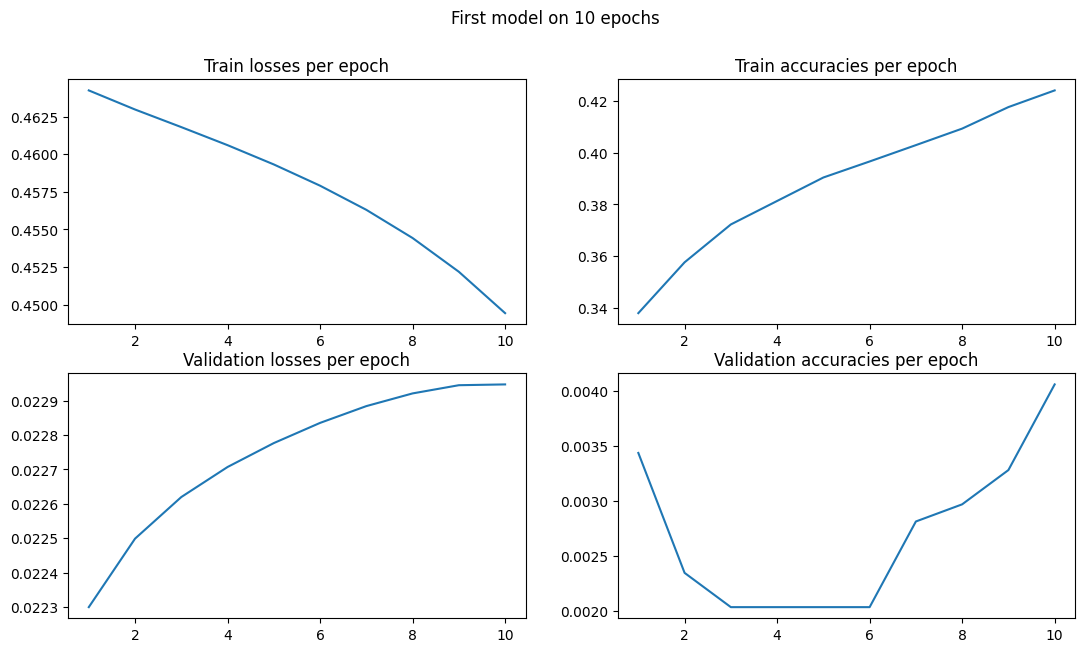

In [42]:
draw_losses_accuracies(10, "First model on 10 epochs", train_losses_1, train_accuracies_1, val_losses_1, val_accuracies_1)

Из-за несбалансированности классов в валидационной выборке показатели там бедовые...

In [28]:
auc_roc = float(get_auc_roc(model_1))
auc_roc

100%|██████████| 21/21 [00:03<00:00,  6.10it/s]


0.6958555369005037

In [29]:
get_score(auc_roc)

1.1981942112562967

###### Вторая модель

In [33]:
set_random_seed(239)

model_2 = ClassificationNet_2(5184, 64).to(device)
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_2.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

train_losses_2, train_accuracies_2, val_losses_2, val_accuracies_2 = train(model_2, optimizer, criterion,
                                                                           train_pairs_loader, val_pairs_loader,
                                                                           10, scheduler, 300, 100)

Training 1/10: 300it [00:42,  7.11it/s]
Validating 1/10: 100it [00:00, 250.58it/s]



Epoch: 1, loss: 0.02184933865442872, accuracy: 0.0028125



Training 2/10: 300it [00:40,  7.40it/s]
Validating 2/10: 100it [00:00, 239.55it/s]



Epoch: 2, loss: 0.02181873582303524, accuracy: 0.0034375



Training 3/10: 300it [00:36,  8.28it/s]
Validating 3/10: 100it [00:00, 238.20it/s]



Epoch: 3, loss: 0.021829119343310596, accuracy: 0.00375



... (10 outputs left out)

Training 9/10: 300it [00:36,  8.27it/s]
Validating 9/10: 100it [00:00, 238.05it/s]



Epoch: 9, loss: 0.021917380504310132, accuracy: 0.0046875



Training 10/10: 300it [00:36,  8.11it/s]
Validating 10/10: 100it [00:01, 85.38it/s]


Epoch: 10, loss: 0.0219355340115726, accuracy: 0.005



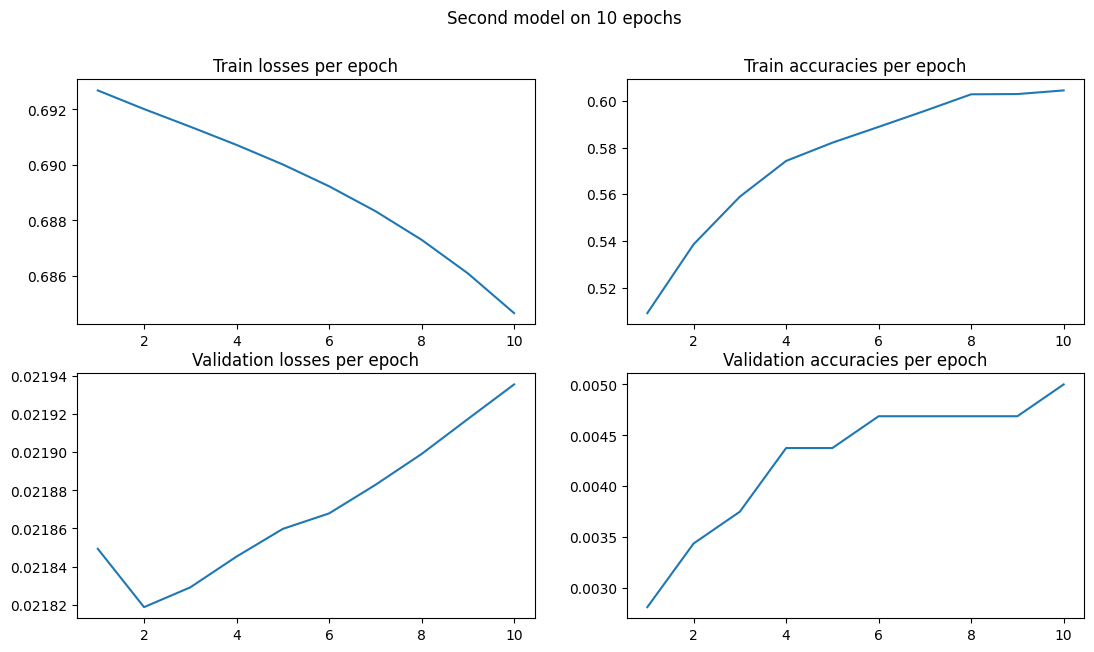

In [38]:
draw_losses_accuracies(10, "Second model on 10 epochs", train_losses_2, train_accuracies_2, val_losses_2, val_accuracies_2)

In [39]:
auc_roc = float(get_auc_roc(model_2))
auc_roc

100%|██████████| 21/21 [00:03<00:00,  5.76it/s]


0.5940324111248996

In [40]:
get_score(auc_roc)

0

Стало хуже...

###### Третья модель

In [46]:
set_random_seed(239)

model_3 = ClassificationNet_3(5184, 64).to(device)
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_3.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

train_losses_3, train_accuracies_3, val_losses_3, val_accuracies_3 = train(model_3, optimizer, criterion,
                                                                           train_pairs_loader, val_pairs_loader,
                                                                           10, scheduler, 300, 100)

Training 1/10: 300it [00:38,  7.83it/s]
Validating 1/10: 100it [00:00, 251.48it/s]



Epoch: 1, loss: 0.023558075558394193, accuracy: 0.0025



Training 2/10: 300it [00:37,  8.05it/s]
Validating 2/10: 100it [00:00, 242.45it/s]



Epoch: 2, loss: 0.023176076542586087, accuracy: 0.0025



Training 3/10: 300it [00:35,  8.37it/s]
Validating 3/10: 100it [00:00, 251.37it/s]



Epoch: 3, loss: 0.022950261998921632, accuracy: 0.0025



... (10 outputs left out)

Training 9/10: 300it [00:43,  6.87it/s]
Validating 9/10: 100it [00:00, 243.18it/s]



Epoch: 9, loss: 0.02259548205882311, accuracy: 0.0025



Training 10/10: 300it [00:36,  8.29it/s]
Validating 10/10: 100it [00:00, 246.73it/s]


Epoch: 10, loss: 0.02256621664389968, accuracy: 0.0025



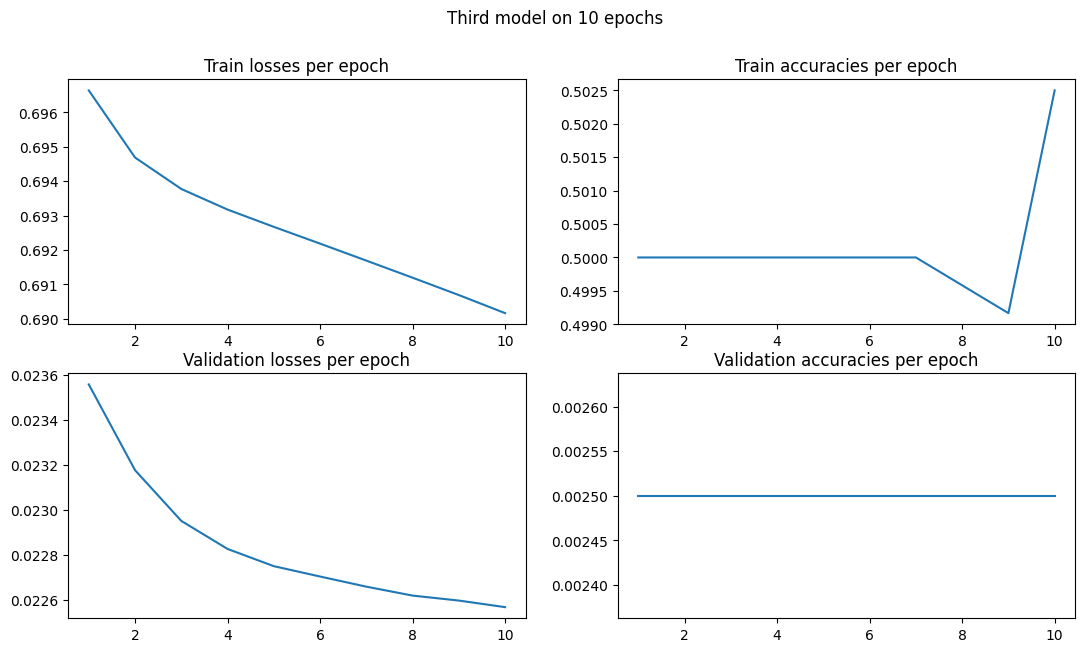

In [47]:
draw_losses_accuracies(10, "Third model on 10 epochs", train_losses_3, train_accuracies_3, val_losses_3, val_accuracies_3)

In [66]:
auc_roc = float(get_auc_roc(model_3))
auc_roc

100%|██████████| 21/21 [00:05<00:00,  3.90it/s]


0.5561427841448281

In [67]:
get_score(auc_roc)

0

Всё ещё плохо...

###### Четвёртая модель

In [53]:
set_random_seed(239)

model_4 = ClassificationNet_4(192, 64).to(device)
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_4.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

train_losses_4, train_accuracies_4, val_losses_4, val_accuracies_4 = train(model_4, optimizer, criterion,
                                                                           train_pairs_loader, val_pairs_loader,
                                                                           10, scheduler, 300, 100)

Training 1/10: 300it [00:31,  9.38it/s]
Validating 1/10: 100it [00:00, 221.05it/s]



Epoch: 1, loss: 0.023233836274594067, accuracy: 0.0025



Training 2/10: 300it [00:31,  9.53it/s]
Validating 2/10: 100it [00:00, 252.94it/s]



Epoch: 2, loss: 0.022946139816194772, accuracy: 0.0025



Training 3/10: 300it [00:30,  9.76it/s]
Validating 3/10: 100it [00:00, 262.44it/s]



Epoch: 3, loss: 0.022724064961075784, accuracy: 0.0025



... (10 outputs left out)

Training 9/10: 300it [00:31,  9.55it/s]
Validating 9/10: 100it [00:00, 260.78it/s]



Epoch: 9, loss: 0.022117913886904716, accuracy: 0.003125



Training 10/10: 300it [00:31,  9.68it/s]
Validating 10/10: 100it [00:00, 216.49it/s]


Epoch: 10, loss: 0.022079805135726927, accuracy: 0.00375



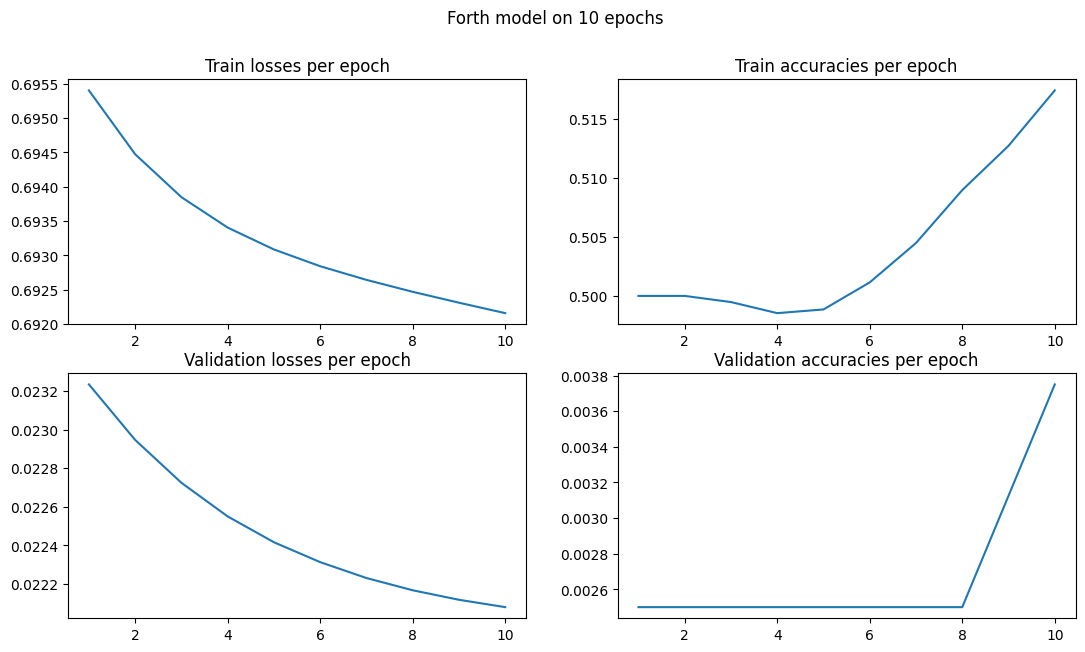

In [144]:
draw_losses_accuracies(10, "Forth model on 10 epochs", train_losses_4, train_accuracies_4, val_losses_4, val_accuracies_4)

In [64]:
auc_roc = float(get_auc_roc(model_4))
auc_roc

100%|██████████| 21/21 [00:06<00:00,  3.41it/s]


0.512599459814585

In [65]:
get_score(auc_roc)

0

Снова лучше не стало...

###### Пятая модель

In [63]:
set_random_seed(239)

model_5 = ClassificationNet_5(9408, 64).to(device)
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_5.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

train_losses_5, train_accuracies_5, val_losses_5, val_accuracies_5 = train(model_5, optimizer, criterion,
                                                                           train_pairs_loader, val_pairs_loader,
                                                                           10, scheduler, 300, 100)

Training 1/10: 300it [00:32,  9.30it/s]
Validating 1/10: 100it [00:00, 224.80it/s]



Epoch: 1, loss: 0.0218041342869401, accuracy: 0.010625



Training 2/10: 300it [00:33,  9.09it/s]
Validating 2/10: 100it [00:00, 181.34it/s]



Epoch: 2, loss: 0.021836970150470734, accuracy: 0.009375



Training 3/10: 300it [00:31,  9.64it/s]
Validating 3/10: 100it [00:00, 265.15it/s]



Epoch: 3, loss: 0.021876187101006507, accuracy: 0.0090625



... (10 outputs left out)

Training 9/10: 300it [00:31,  9.41it/s]
Validating 9/10: 100it [00:00, 269.59it/s]



Epoch: 9, loss: 0.021218770053237676, accuracy: 0.0171875



Training 10/10: 300it [00:31,  9.64it/s]
Validating 10/10: 100it [00:00, 264.15it/s]


Epoch: 10, loss: 0.020668676327914, accuracy: 0.01875



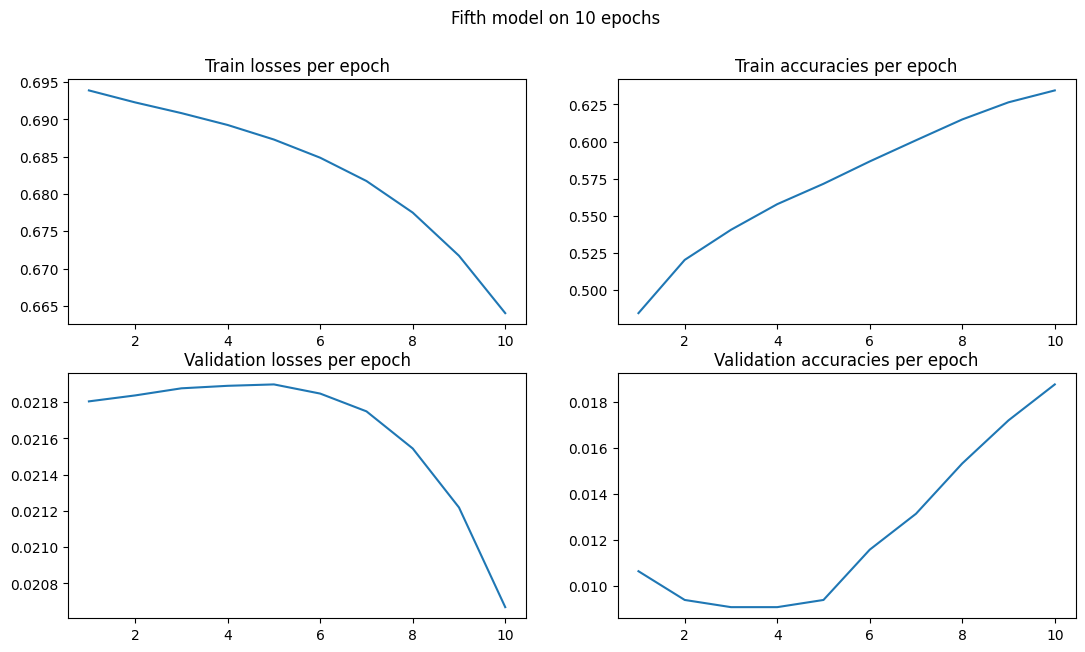

In [145]:
draw_losses_accuracies(10, "Fifth model on 10 epochs", train_losses_5, train_accuracies_5, val_losses_5, val_accuracies_5)

In [68]:
auc_roc = float(get_auc_roc(model_5))
auc_roc

100%|██████████| 21/21 [00:06<00:00,  3.45it/s]


0.6113949923352069

In [69]:
get_score(auc_roc)

0.14243740419008638

###### Шестая модель

In [72]:
set_random_seed(239)

model_6 = ClassificationNet_6(254016, 64).to(device)
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_6.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

train_losses_6, train_accuracies_6, val_losses_6, val_accuracies_6 = train(model_6, optimizer, criterion,
                                                                           train_pairs_loader, val_pairs_loader,
                                                                           10, scheduler, 300, 100)

Training 1/10: 300it [00:44,  6.81it/s]
Validating 1/10: 100it [00:00, 162.49it/s]



Epoch: 1, loss: 0.023080386463552715, accuracy: 0.0075



Training 2/10: 300it [00:45,  6.62it/s]
Validating 2/10: 100it [00:00, 206.13it/s]



Epoch: 2, loss: 0.022702012974768877, accuracy: 0.0121875



Training 3/10: 300it [00:44,  6.79it/s]
Validating 3/10: 100it [00:00, 210.94it/s]



Epoch: 3, loss: 0.022427606321871282, accuracy: 0.0128125



... (10 outputs left out)

Training 9/10: 300it [00:46,  6.44it/s]
Validating 9/10: 100it [00:00, 206.44it/s]



Epoch: 9, loss: 0.02089489988517016, accuracy: 0.02



Training 10/10: 300it [00:45,  6.64it/s]
Validating 10/10: 100it [00:00, 206.18it/s]


Epoch: 10, loss: 0.02078055441379547, accuracy: 0.0203125



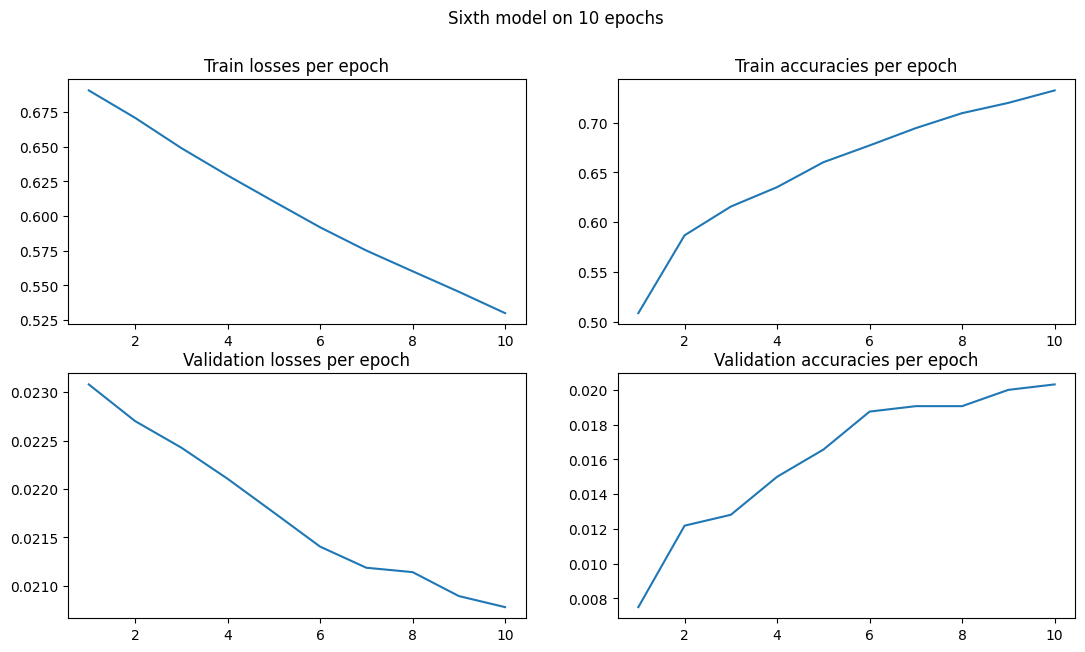

In [146]:
draw_losses_accuracies(10, "Sixth model on 10 epochs", train_losses_6, train_accuracies_6, val_losses_6, val_accuracies_6)

In [73]:
auc_roc = float(get_auc_roc(model_6))
auc_roc

100%|██████████| 21/21 [00:09<00:00,  2.23it/s]


0.698580188334915

In [74]:
get_score(auc_roc)

1.2322523541864374

###### Седьмая модель

In [78]:
set_random_seed(239)

model_7 = ClassificationNet_7(93312, 64).to(device)
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_7.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

train_losses_7, train_accuracies_7, val_losses_7, val_accuracies_7 = train(model_7, optimizer, criterion,
                                                                           train_pairs_loader, val_pairs_loader,
                                                                           10, scheduler, 300, 100)

Training 1/10: 300it [01:10,  4.26it/s]
Validating 1/10: 100it [00:00, 104.59it/s]



Epoch: 1, loss: 0.02287399722263217, accuracy: 0.0025



Training 2/10: 300it [01:11,  4.20it/s]
Validating 2/10: 100it [00:00, 109.52it/s]



Epoch: 2, loss: 0.02289501316845417, accuracy: 0.004375



Training 3/10: 300it [01:20,  3.72it/s]
Validating 3/10: 100it [00:00, 112.63it/s]



Epoch: 3, loss: 0.022669867184013127, accuracy: 0.0090625



... (10 outputs left out)

Training 9/10: 300it [01:09,  4.34it/s]
Validating 9/10: 100it [00:00, 118.56it/s]



Epoch: 9, loss: 0.02183045622892678, accuracy: 0.0146875



Training 10/10: 300it [01:08,  4.38it/s]
Validating 10/10: 100it [00:00, 124.70it/s]


Epoch: 10, loss: 0.0217118027061224, accuracy: 0.014375



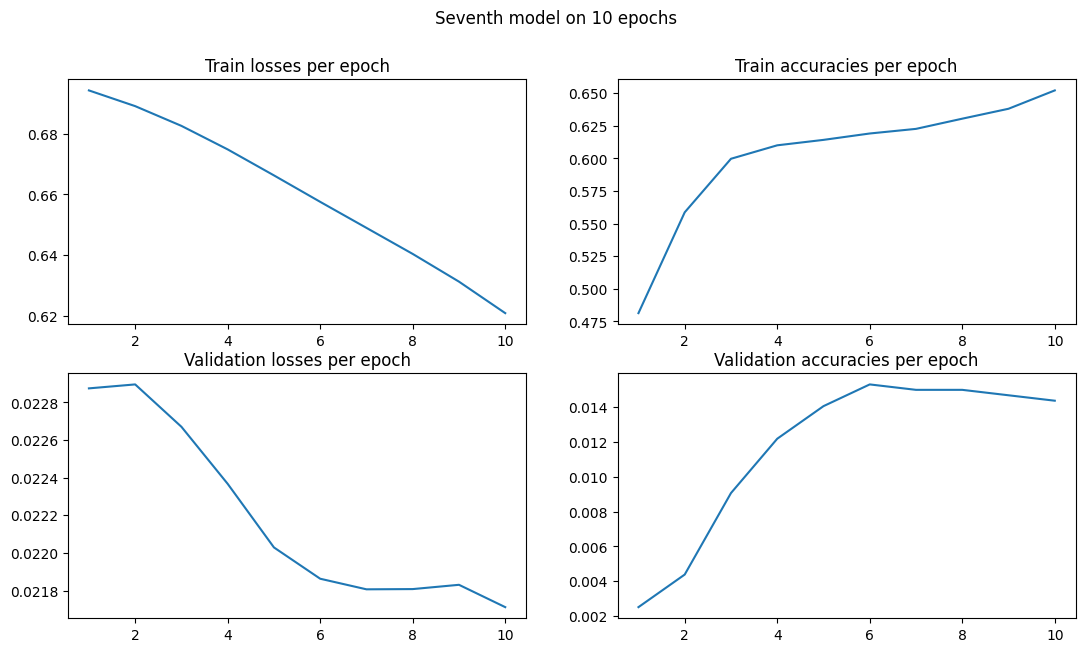

In [147]:
draw_losses_accuracies(10, "Seventh model on 10 epochs", train_losses_7, train_accuracies_7, val_losses_7, val_accuracies_7)

In [79]:
auc_roc = float(get_auc_roc(model_7))
auc_roc

100%|██████████| 21/21 [00:08<00:00,  2.34it/s]


0.6810825607708593

In [80]:
get_score(auc_roc)

1.013532009635741

###### Восьмая модель = первая на 20 эпохах

In [89]:
set_random_seed(239)

model_8 = ClassificationNet_1(5184, 64).to(device)
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_8.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

train_losses_8, train_accuracies_8, val_losses_8, val_accuracies_8 = train(model_8, optimizer, criterion,
                                                                           train_pairs_loader, val_pairs_loader,
                                                                           20, scheduler, 200, 50)

Training 1/20: 200it [00:25,  7.81it/s]
Validating 1/20: 50it [00:00, 231.46it/s]



Epoch: 1, loss: 0.02214162588119507, accuracy: 0.006875



Training 2/20: 200it [00:24,  8.09it/s]
Validating 2/20: 50it [00:00, 223.85it/s]



Epoch: 2, loss: 0.02217510599642992, accuracy: 0.00625



Training 3/20: 200it [00:26,  7.50it/s]
Validating 3/20: 50it [00:00, 237.06it/s]



Epoch: 3, loss: 0.022194333001971246, accuracy: 0.006875



... (30 outputs left out)

Training 19/20: 200it [00:28,  7.09it/s]
Validating 19/20: 50it [00:00, 235.83it/s]



Epoch: 19, loss: 0.022138168402016163, accuracy: 0.011875



Training 20/20: 200it [00:24,  8.28it/s]
Validating 20/20: 50it [00:00, 243.89it/s]


Epoch: 20, loss: 0.022046726904809476, accuracy: 0.0125



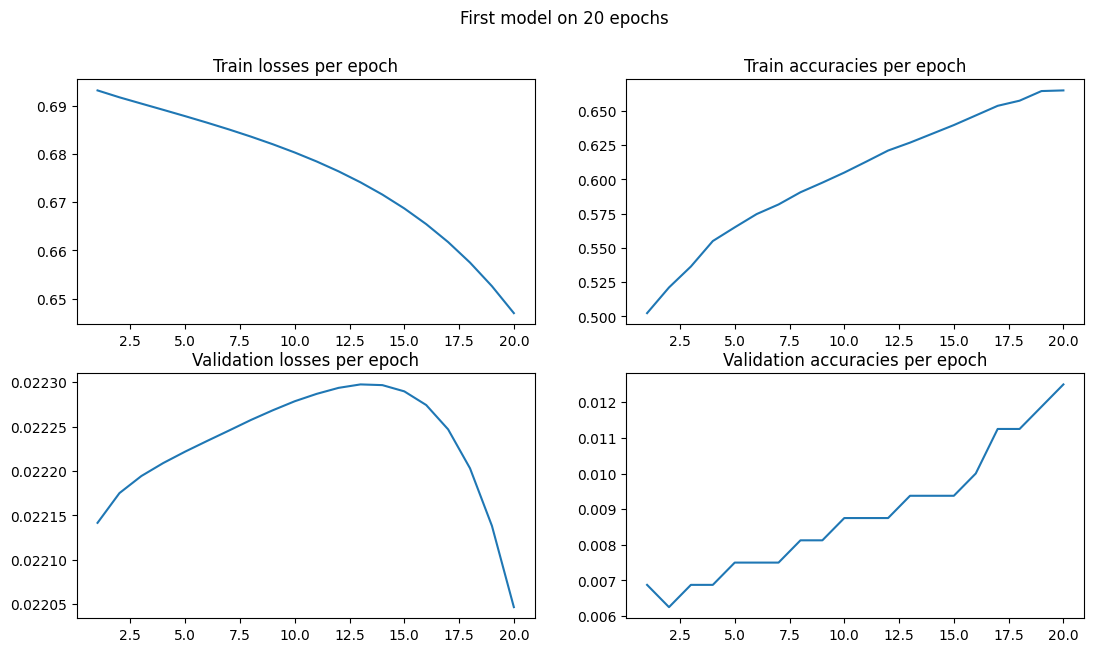

In [96]:
draw_losses_accuracies(20, "First model on 20 epochs", train_losses_8, train_accuracies_8, val_losses_8, val_accuracies_8)

In [90]:
auc_roc = float(get_auc_roc(model_8))
auc_roc

100%|██████████| 21/21 [00:07<00:00,  2.65it/s]


0.7289984670413898

In [91]:
get_score(auc_roc)

1.612480838017373

###### Девятая модель = шестая на 20 эпохах

In [93]:
set_random_seed(239)

model_9 = ClassificationNet_6(254016, 64).to(device)
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_9.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

train_losses_9, train_accuracies_9, val_losses_9, val_accuracies_9 = train(model_9, optimizer, criterion,
                                                                           train_pairs_loader, val_pairs_loader,
                                                                           20, scheduler, 200, 50)

Training 1/20: 200it [00:29,  6.74it/s]
Validating 1/20: 50it [00:00, 209.31it/s]



Epoch: 1, loss: 0.021651951782405376, accuracy: 0.021875



Training 2/20: 200it [00:34,  5.88it/s]
Validating 2/20: 50it [00:00, 160.05it/s]



Epoch: 2, loss: 0.021860607601702213, accuracy: 0.014375



Training 3/20: 200it [00:31,  6.32it/s]
Validating 3/20: 50it [00:00, 193.09it/s]



Epoch: 3, loss: 0.0219905686378479, accuracy: 0.0125



... (30 outputs left out)

Training 19/20: 200it [00:28,  6.92it/s]
Validating 19/20: 50it [00:00, 213.39it/s]



Epoch: 19, loss: 0.029109055001754314, accuracy: 0.016875



Training 20/20: 200it [00:29,  6.79it/s]
Validating 20/20: 50it [00:00, 193.52it/s]


Epoch: 20, loss: 0.02953829724690877, accuracy: 0.01625



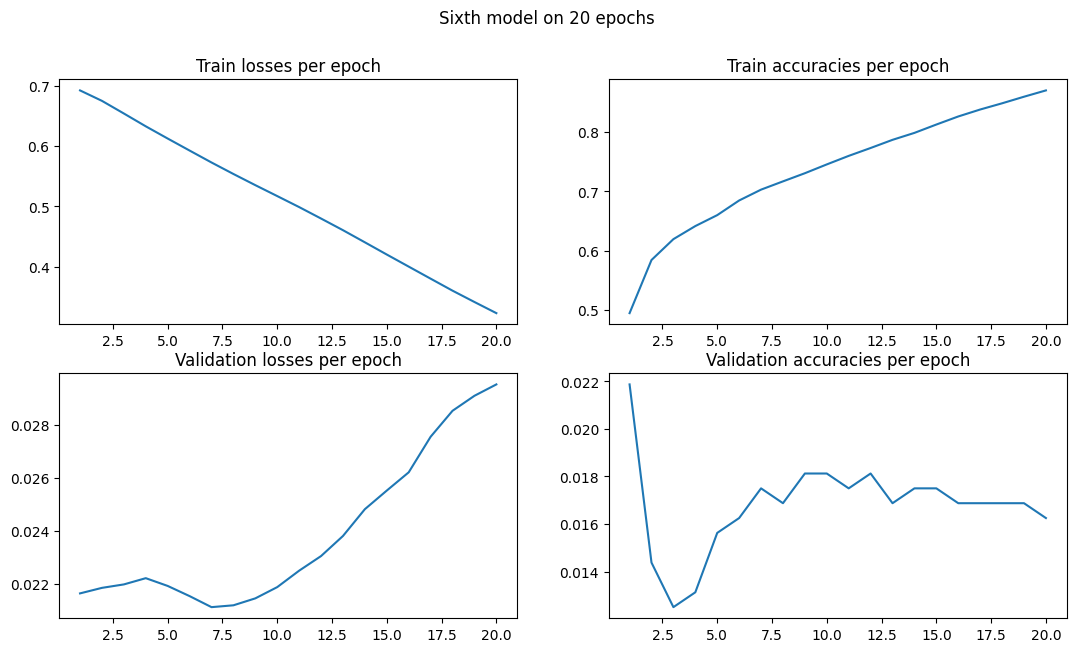

In [102]:
draw_losses_accuracies(20, "Sixth model on 20 epochs", train_losses_9, train_accuracies_9, val_losses_9, val_accuracies_9)

In [94]:
auc_roc = float(get_auc_roc(model_9))
auc_roc

100%|██████████| 21/21 [00:08<00:00,  2.38it/s]


0.6525476312139573

In [95]:
get_score(auc_roc)

0.6568453901744666

###### **!Лучшая!** Десятая модель = первая на 60 эпохах

In [97]:
set_random_seed(239)

model_10 = ClassificationNet_1(5184, 64).to(device)
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_10.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

train_losses_10, train_accuracies_10, val_losses_10, val_accuracies_10 = train(model_10, optimizer, criterion,
                                                                           train_pairs_loader, val_pairs_loader,
                                                                           60, scheduler, 200, 50)

Training 1/60: 200it [00:23,  8.43it/s]
Validating 1/60: 50it [00:00, 245.13it/s]



Epoch: 1, loss: 0.02214162588119507, accuracy: 0.006875



Training 2/60: 200it [00:23,  8.35it/s]
Validating 2/60: 50it [00:00, 246.91it/s]



Epoch: 2, loss: 0.02217510599642992, accuracy: 0.00625



Training 3/60: 200it [00:23,  8.35it/s]
Validating 3/60: 50it [00:00, 234.83it/s]



Epoch: 3, loss: 0.022194333001971246, accuracy: 0.006875



... (110 outputs left out)

Training 59/60: 200it [00:34,  5.77it/s]
Validating 59/60: 50it [00:00, 249.44it/s]



Epoch: 59, loss: 0.020971327740699052, accuracy: 0.01875



Training 60/60: 200it [00:34,  5.78it/s]
Validating 60/60: 50it [00:00, 226.04it/s]


Epoch: 60, loss: 0.02113900162279606, accuracy: 0.01875



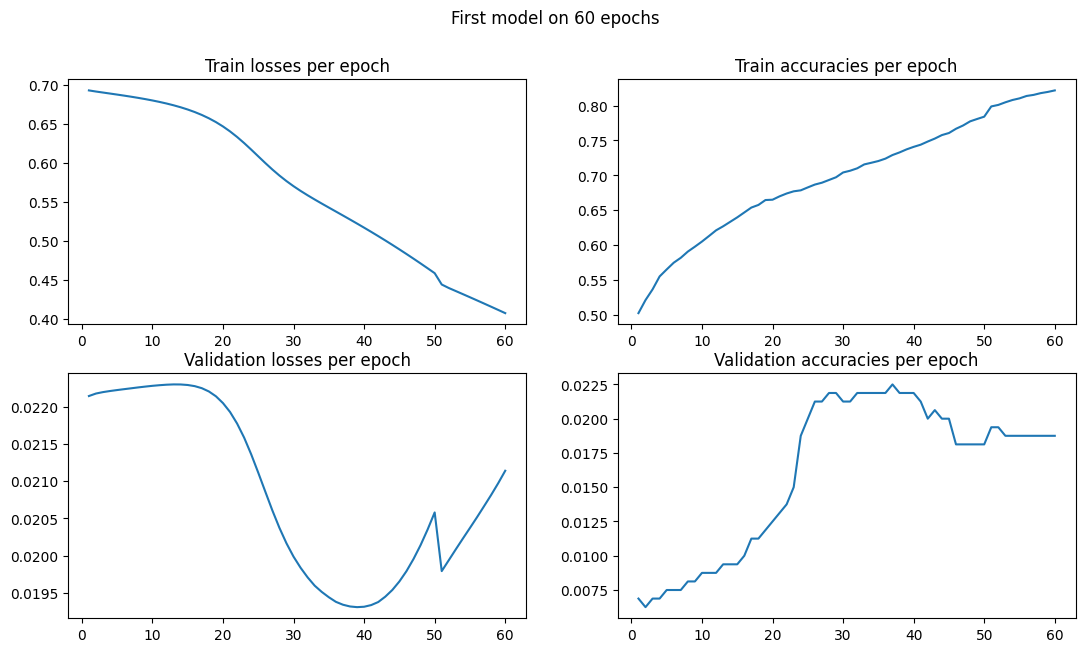

In [103]:
draw_losses_accuracies(60, "First model on 60 epochs", train_losses_10, train_accuracies_10, val_losses_10, val_accuracies_10)

Она жёстко переобучается, но AUC-ROC получается хороший :)

In [100]:
auc_roc = float(get_auc_roc(model_10))
auc_roc

100%|██████████| 21/21 [00:06<00:00,  3.49it/s]


0.7842616249361267

In [101]:
get_score(auc_roc)

2.303270311701584

##### [0.5 балла] Задание 2.3. Анализ и отчет.

Опишите свои эксперименты. Проанализируйте результаты. Почему результаты получились не очень хорошими? Может быть, решать задачу через бинарную классификацию - не лучшая идея? Приведите не менее 3 аргументов, почему это так.

**Описание экспериментов**

1. Базовая модель: состоит из трёх свёрточных слоёв и двух полносвязных. AUC-ROC = 0,695...
2. Добавили нелинейности после каждого слоя. AUC-ROC = 0,59...
3. Оставили ReLU только в полносвязных слоях и добавили ещё один полносвязный слой. AUC-ROC = 0,55...
4. Сделали меньше каналов в свёрточных слоях, чем в третьей модели. AUC-ROC = 0,51...
5. Оставили MaxPooling только после последнего свёрточного слоя в четвёртой модели. AUC-ROC = 0,61...
6. Вернулись к первой модели и оставили MaxPooling только после последнего свёрточного слоя. AUC-ROC = 0,698...
7. Добавили в шестую модель ещё один свёрточный слой. AUC-ROC = 0,68...
8. Прогнали базовую модель на 20 эпохах. AUC-ROC = 0,728...
9. Прогнали шестую модель на 30 эпохах. AUC-ROC = 0,65...
10. **!Лучший score!** Прогнали базовую модель на 60 эпохах. AUC-ROC = 0,784...

**Итоги**

Лучший результат - AUC-ROC = 0,784, score = 2,30... Добились на неприличном количестве эпох базовой модели. Вывод: эпохи решают.

Дополнительные выводы:
* Не нужно сувать слишком много нелинейностей;
* Чем больше каналов в свёрточных сетях, тем лучше - но главное, чтобы к переходу к полносвязным сетям вектор был не слишком длинный, а то обучение будет безумно долгим;
* Стоит не перебарщивать с MaxPooling'ами;
* Много свёрточных слоёв тоже дают неплохой результат.

**Почему бинарная классификация не очень хорошо подходит для этой задачи**

1. Конкатенирование картинок тем или иным способом никак не отражает суть задачи: модель не учится находить похожее и различное, а потому она не точна в своих прогнозах.
2. В этом методе мы не даём модели запомнить черты разных знаменитостей, чтобы она потом могла их сравнивать между собой - это бы очень помогло ей (+ именно так действуют живые люди при выполнении этой задачи).
3. В бинарной классификации не учитывается, что различие между людьми - это шкала: какие-то люди похожи больше, какие-то меньше. Понимание степени различия улучшило бы результаты модели.

### [5 баллов] Часть 3. Распознавание лиц.

Теперь попробуем использовать более хитрые методы, которые лучше подходят для решаемой задачи. В частности, триплетную функцию потерь. Далее наша модель будет не предсказывать вероятность для двух картинок, а формировать эмбеддинги для одной картинки таким образом, чтобы эмбеддинги фотографий одного человека были близки, а разных людей - далеки.

##### [2 балла] Задание 3.1. Триплетная функция потерь.

Напомним теорию. Пусть $A$ - произвольное изображение; $P$ - изображение того же человека (позитивный пример); $N$ - изображение любого другого человека (негативный пример); $f$ - наша нейронная сеть; $\alpha$ - гиперпараметр, отвечающий за желаемый “отступ” – расстояние между латентными представлениями изображений разных людей. Тогда функционал ошибки определяется следующим образом:

$$ L(A, P, N) = max(||f(A) - f(P)|| - ||f(A) - f(N)|| + \alpha, 0) $$

В этом задании вам необходимо реализовать этот функционал. Для удобства в дальнейшем, предлагается сразу реализовать batch-версию. Таким образом, на входе должно быть 2 параметра:
- Набор эмбеддингов размера (batch_size, embedding_size)
- Набор классов (номера людей, чьи это фотографии) размера (batch_size)

Ваша функция должна найти все тройки $(A, P, N)$ и вычислить лосс для них.

В `pytorch_metric_learning` уже есть готовая реализация. Вы можете её найти и использовать. Но в таком случае __максимальный балл за это задание - 0.5__.

In [154]:
# Структура APN отсюда:
# https://www.kaggle.com/code/hirotaka0122/triplet-loss-with-pytorch

class TripletLoss(torch.nn.Module):
    def __init__(self, margin=0.25):
        super().__init__()
        self.margin = margin

    def forward(self, embeds, labels):
        # Создаём словарь, где ключи - (индекс1, индекс2, лэйбл), а значения - список индексов несовпадающих лэйблов
        same_pairs_dict = {}
        anchor, positive, negative = [], [], []

        for i in range(len(labels) - 1):
            for j in range(i + 1, len(labels)):

                if labels[i] == labels[j]:
                    key = (i, j, labels[i])
                    same_pairs_dict[key] = list(range(len(labels)))

                    # Удаляем индексы совпадающих лэйблов из values
                    for k in range(len(same_pairs_dict[key]) - 1, -1, -1):
                        if labels[same_pairs_dict[key][k]] == key[2]:
                            same_pairs_dict[key].pop(k)

                    len_now = len(same_pairs_dict[key])
                    # Заполняем списки соответствующими картинками
                    anchor.extend([embeds[i].tolist()] * len_now)
                    positive.extend([embeds[j].tolist()] * len_now)
                    negative.extend([embeds[idx].tolist() for idx in same_pairs_dict[key]])

        # print(f"Anchor: {anchor}\nPositive: {positive}\nNegative: {negative}")
        anchor, positive, negative = torch.tensor(anchor), torch.tensor(positive), torch.tensor(negative)

        distance_positive = (anchor - positive).abs()
        distance_negative = (anchor - negative).abs()
        losses = torch.relu(distance_positive - distance_negative + self.margin)

        return losses.mean()

In [155]:
criterion = TripletLoss(0.25)

In [156]:
# Вы можете использовать этот ассерт в качестве теста
embeddings = torch.tensor([
    [ 1., 2, 3 ],
    [ 1, 3, 4 ],
    [ 4, 5, 6 ]
])
labels = torch.tensor([ 1., 2, 1 ])
assert (criterion(embeddings, labels) - 2.6775) < 1e-4

Anchor: [[1.0, 2.0, 3.0]]
Positive: [[4.0, 5.0, 6.0]]
Negative: [[1.0, 3.0, 4.0]]


 Ответ правильный!!